### Prof. Alfio Ferrara

# Il testo

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Finora abbiamo lavorato con numeri, immagini e griglie. Ora passiamo al materiale più familiare per chi studia discipline umanistiche: il **testo**.

## Che cosa vogliamo fare con il testo

Un archivio contiene migliaia di documenti: lettere, articoli, verbali, romanzi. Nessuno può leggerli tutti. Ci sono tre cose che vorremmo poter chiedere a un programma.

**1. Ricerca di documenti.** Dato un bisogno informativo, espresso con qualche parola, vogliamo ritrovare i documenti che parlano di quell'argomento. Per esempio: *«le lettere in cui si discute di viaggi per mare»*.

**2. Classificazione.** Dato un documento nuovo, vogliamo assegnarlo a una categoria che conosciamo già: il genere di un testo, l'autore, l'argomento, il tono. Per esempio: *«questo articolo è di cronaca o di sport?»*.

**3. Generazione.** Vogliamo che il programma produca un testo nuovo: continuare una frase, riassumere un documento, rispondere a una domanda.

I tre compiti sembrano molto diversi, ma i primi due hanno un'idea in comune. In entrambi dobbiamo **confrontare** dei testi: nella ricerca confrontiamo la richiesta con i documenti, nella classificazione confrontiamo il documento nuovo con quelli già etichettati. Per poter confrontare, però, un programma ha bisogno di numeri, e abbiamo già visto che un testo si può codificare, ma la codifica dei caratteri non ci dice nulla sul *significato*.

Il percorso di questo notebook è il seguente:

1. prima ci chiediamo come si possano **confrontare degli oggetti** a partire dalle sole loro componenti, e lo facciamo con un piccolo insieme di dati che non è testo;
2. da qui ricaviamo l'idea di **spazio vettoriale**, che ci servirà sia per la ricerca sia per la classificazione;
3. infine applichiamo la stessa idea ai testi: ciò che nell'esempio erano le *caratteristiche* degli oggetti diventeranno le **parole**.

La generazione richiede qualche strumento in più e ci arriveremo alla fine.

## Confrontare oggetti: città e climi

Cominciamo da un problema che non riguarda ancora il testo. Abbiamo alcune città e vogliamo sapere **quali si assomigliano** dal punto di vista del clima.

Per ognuna conosciamo soltanto due numeri:

- la **temperatura media annua**, in °C;
- le **precipitazioni annue**, in mm.

I valori sono approssimati e servono a scopo didattico.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
citta = ['Singapore', 'Bangkok', 'Riyad', 'Assuan', 'Roma',
         'Barcellona', 'Londra', 'Mosca', 'Reykjavik', 'Jakutsk']
temperatura = [27, 29, 26, 26, 16, 16, 11, 6, 4, -9]
precipitazioni = [2300, 1500, 100, 1, 800, 600, 600, 700, 800, 240]

tabella = pd.DataFrame({'temperatura': temperatura, 'precipitazioni': precipitazioni}, index=citta)
tabella

,temperatura,precipitazioni
Singapore,27,2300
Bangkok,29,1500
Riyad,26,100
Assuan,26,1
Roma,16,800
Barcellona,16,600
Londra,11,600
Mosca,6,700
Reykjavik,4,800
Jakutsk,-9,240


## Dalla tabella al piano

Ogni riga della tabella è una coppia di numeri. Una coppia di numeri è un **punto nel piano**: usiamo la temperatura come ascissa e le precipitazioni come ordinata. La tabella e il grafico contengono la stessa informazione, scritta in due modi.

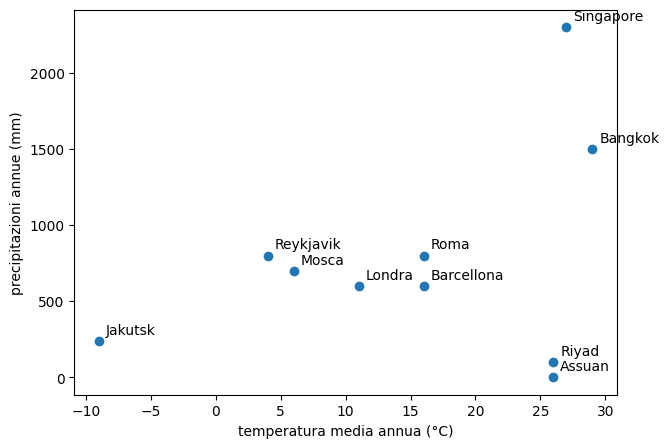

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(tabella['temperatura'], tabella['precipitazioni'])
for nome, riga in tabella.iterrows():
    ax.annotate(nome, (riga['temperatura'], riga['precipitazioni']), xytext=(5, 5), textcoords='offset points')
ax.set_xlabel('temperatura media annua (°C)')
ax.set_ylabel('precipitazioni annue (mm)')
plt.show()

Sul grafico si vedono dei gruppi: le città calde e piovose in alto a destra, quelle calde e asciutte in basso a destra, quelle fredde a sinistra. Intuitivamente, due città **vicine** nel piano hanno un clima simile.

Per trasformare questa intuizione in un calcolo ci serve una misura di vicinanza. Nel piano la scelta più naturale è la **distanza euclidea**, cioè la lunghezza del segmento che unisce due punti. Se $a = (a_1, a_2)$ e $b = (b_1, b_2)$:

$$d(a, b) = \sqrt{(a_1 - b_1)^2 + (a_2 - b_2)^2}$$

Nel nostro caso $a_1$ e $b_1$ sono due temperature, $a_2$ e $b_2$ due precipitazioni.

In [4]:
def distanza(a, b):
    return np.sqrt(np.sum((np.array(a) - np.array(b)) ** 2))

def piu_simili(punti, nome, k=3):
    """Le k città più vicine a `nome`, con la loro distanza."""
    distanze = punti.apply(lambda riga: distanza(riga, punti.loc[nome]), axis=1)
    return distanze.drop(nome).sort_values().head(k)

In [5]:
piu_simili(tabella, 'Roma')

Reykjavik      12.000000
Mosca         100.498756
Barcellona    200.000000
dtype: float64

### Il risultato vi convince?

- Quale città è risultata la più simile a Roma? E la seconda?
- Barcellona è sul Mediterraneo, come Roma. Dov'è finita?
- Guardate di nuovo la tabella: quale delle due colonne decide quasi da sola l'esito del confronto? Perché?

## Quando le scale sono diverse

Le temperature variano tra −9 e 29, cioè di una trentina di unità. Le precipitazioni variano tra 1 e 2300. Nella formula della distanza una differenza di 200 mm pesa moltissimo, mentre una differenza di 12 °C quasi non conta.

Lo vediamo bene se disegniamo gli stessi punti dando la stessa lunghezza a un'unità sui due assi.

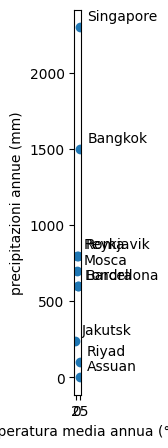

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(tabella['temperatura'], tabella['precipitazioni'])
for nome, riga in tabella.iterrows():
    ax.annotate(nome, (riga['temperatura'], riga['precipitazioni']), xytext=(5, 5), textcoords='offset points')
ax.set_aspect('equal')
ax.set_xlabel('temperatura media annua (°C)')
ax.set_ylabel('precipitazioni annue (mm)')
plt.show()

Tutte le città si schiacciano su una striscia verticale. La temperatura, in pratica, **non fa più parte del confronto**: ci siamo ridotti a una sola dimensione.

Il rimedio è portare le due colonne sulla stessa scala. Il modo più semplice è la **normalizzazione min-max**: per ogni colonna sottraiamo il valore minimo e dividiamo per l'ampiezza, così che il valore più basso diventi 0 e il più alto 1.

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

In [7]:
scalata = (tabella - tabella.min()) / (tabella.max() - tabella.min())
scalata.round(2)

,temperatura,precipitazioni
Singapore,0.95,1.00
Bangkok,1.00,0.65
Riyad,0.92,0.04
Assuan,0.92,0.00
Roma,0.66,0.35
Barcellona,0.66,0.26
Londra,0.53,0.26
Mosca,0.39,0.30
Reykjavik,0.34,0.35
Jakutsk,0.00,0.10


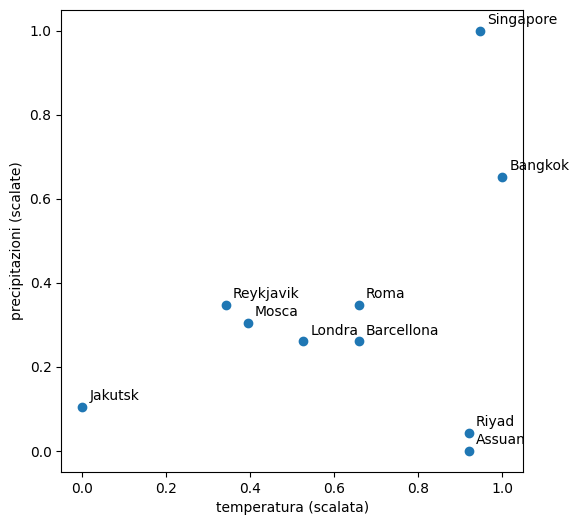

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(scalata['temperatura'], scalata['precipitazioni'])
for nome, riga in scalata.iterrows():
    ax.annotate(nome, (riga['temperatura'], riga['precipitazioni']), xytext=(5, 5), textcoords='offset points')
ax.set_aspect('equal')
ax.set_xlabel('temperatura (scalata)')
ax.set_ylabel('precipitazioni (scalate)')
plt.show()

In [9]:
piu_simili(scalata, 'Roma')

Barcellona    0.086994
Londra        0.157737
Mosca         0.266728
dtype: float64

### Cosa è cambiato?

- Qual è ora la città più simile a Roma?
- Ora entrambe le colonne contribuiscono al confronto. Come lo vediamo sul grafico?
- Lo scaling ha cambiato i dati o il modo in cui li guardiamo? Le città sono sempre le stesse e le informazioni anche: cosa è diverso?

## Altri modi di misurare la vicinanza

Ogni riga della tabella è un **vettore**: una sequenza ordinata di numeri, uno per colonna. Roma, nella tabella scalata, è il vettore $(0{,}66;\ 0{,}35)$. Geometricamente è un punto nel piano, ma possiamo vederlo anche come una **freccia** che parte dall'origine e arriva in quel punto.

La distanza euclidea misura quanto sono lontane le punte di due frecce. Ma non è l'unico modo di confrontare due vettori. Ne vediamo altri due, che si basano su un'operazione diversa.

### Prodotto scalare

Il **prodotto scalare** di due vettori $a$ e $b$ si calcola moltiplicando le componenti nella stessa posizione e sommando i risultati:

$$a \cdot b = a_1 b_1 + a_2 b_2$$

È un solo numero. È grande quando i due vettori hanno valori alti *nelle stesse colonne*, ed è piccolo quando uno è alto dove l'altro è basso. Ha anche un significato geometrico:

$$a \cdot b = \|a\| \, \|b\| \cos\theta$$

dove $\|a\| = \sqrt{a_1^2 + a_2^2}$ è la **lunghezza** della freccia (la norma) e $\theta$ è l'angolo tra le due frecce.

### Similarità del coseno

Nel prodotto scalare contano sia la lunghezza delle frecce sia l'angolo. Se vogliamo confrontare solo la **direzione**, dividiamo per le lunghezze:

$$\cos\theta = \frac{a \cdot b}{\|a\| \, \|b\|}$$

Questa è la **similarità del coseno**: vale 1 se i due vettori puntano nella stessa direzione e diminuisce all'aumentare dell'angolo. La **distanza del coseno** è semplicemente $1 - \cos\theta$, così che valga 0 per vettori con la stessa direzione, come ci aspettiamo da una distanza.

In [10]:
def prodotto_scalare(a, b):
    return np.sum(np.array(a) * np.array(b))

def norma(a):
    return np.sqrt(prodotto_scalare(a, a))

def similarita_coseno(a, b):
    return prodotto_scalare(a, b) / (norma(a) * norma(b))

def distanza_coseno(a, b):
    return 1 - similarita_coseno(a, b)

Confrontiamo Roma con tutte le altre città usando le tre misure, sulla tabella scalata.

In [11]:
roma = scalata.loc['Roma']

confronto = pd.DataFrame({
    'distanza euclidea': scalata.apply(lambda riga: distanza(riga, roma), axis=1),
    'prodotto scalare': scalata.apply(lambda riga: prodotto_scalare(riga, roma), axis=1),
    'similarità coseno': scalata.apply(lambda riga: similarita_coseno(riga, roma), axis=1),
    'distanza coseno': scalata.apply(lambda riga: distanza_coseno(riga, roma), axis=1),
}).drop('Roma')

confronto.round(3)

,distanza euclidea,prodotto scalare,similarità coseno,distanza coseno
Singapore,0.714,0.971,0.947,0.053
Bangkok,0.458,0.885,0.996,0.004
Riyad,0.402,0.621,0.905,0.095
Assuan,0.436,0.606,0.884,0.116
Barcellona,0.087,0.523,0.994,0.006
Londra,0.158,0.437,1.000,0.000
Mosca,0.267,0.365,0.986,0.014
Reykjavik,0.316,0.346,0.953,0.047
Jakutsk,0.702,0.036,0.467,0.533


Per vedere la geometria disegniamo le città come frecce dall'origine.

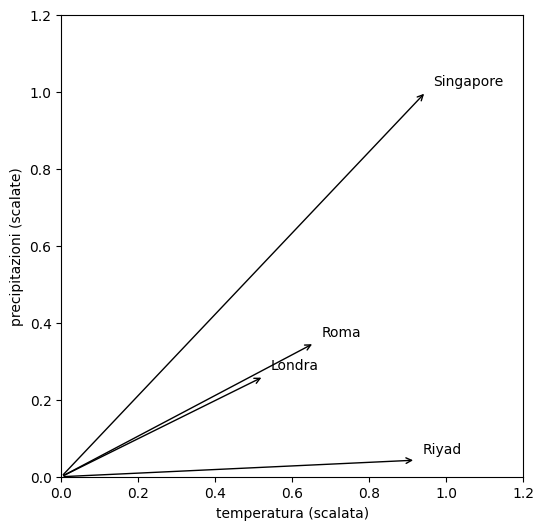

In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
for nome in ['Roma', 'Londra', 'Singapore', 'Riyad']:
    x, y = scalata.loc[nome, 'temperatura'], scalata.loc[nome, 'precipitazioni']
    ax.annotate('', xy=(x, y), xytext=(0, 0), arrowprops=dict(arrowstyle='->'))
    ax.annotate(nome, (x, y), xytext=(5, 5), textcoords='offset points')
ax.set_xlim(0, 1.2)
ax.set_ylim(0, 1.2)
ax.set_aspect('equal')
ax.set_xlabel('temperatura (scalata)')
ax.set_ylabel('precipitazioni (scalate)')
plt.show()

### Tre misure, tre risposte

- Nella colonna del prodotto scalare, quale città risulta più simile a Roma? Perché secondo voi? Guardate la lunghezza della sua freccia.
- Roma e Londra hanno una similarità del coseno praticamente uguale a 1. Cosa significa sul grafico? Hanno lo stesso clima?
- Quale misura sceglieremmo per dire che due città hanno lo stesso clima? E quale per dire che i loro valori sono *proporzionali*?

## Intensità e proporzioni

Il coseno ignora la lunghezza dei vettori e guarda solo le **proporzioni** tra le componenti. Lo verifichiamo con un esempio estremo: prendiamo Roma e una città immaginaria che ha esattamente il doppio di temperatura e di precipitazioni (in valori scalati).

In [13]:
roma = scalata.loc['Roma'].values
roma_doppia = 2 * roma

print('distanza euclidea:', round(distanza(roma, roma_doppia), 3))
print('similarità coseno:', round(similarita_coseno(roma, roma_doppia), 3))

distanza euclidea: 0.744
similarità coseno: 1.0


Per la distanza euclidea le due città sono lontane, per il coseno sono identiche. Nessuna delle due risposte è sbagliata: rispondono a domande diverse. La distanza euclidea chiede *«hanno gli stessi valori?»*, il coseno chiede *«hanno le stesse proporzioni?»*.

Quando passeremo al testo questa differenza diventerà decisiva. Un documento lungo e uno breve che parlano dello stesso argomento useranno le stesse parole nelle stesse proporzioni, ma il lungo le ripeterà molte più volte: sarà come la nostra Roma raddoppiata.

## Più di due dimensioni

Due caratteristiche non bastano a descrivere un clima: Londra e Roma hanno precipitazioni simili, ma estati e inverni molto diversi. Aggiungiamo altre due colonne:

- l'**escursione termica annua**, cioè la differenza in °C tra il mese più caldo e il più freddo;
- le **ore di sole** all'anno.

Anche questi valori sono approssimati.

In [14]:
escursione = [2, 5, 21, 18, 16, 14, 14, 25, 11, 58]
ore_di_sole = [2000, 2700, 3400, 3900, 2500, 2500, 1500, 1700, 1300, 2000]

tabella4 = tabella.copy()
tabella4['escursione'] = escursione
tabella4['ore_di_sole'] = ore_di_sole
tabella4

,temperatura,precipitazioni,escursione,ore_di_sole
Singapore,27,2300,2,2000
Bangkok,29,1500,5,2700
Riyad,26,100,21,3400
Assuan,26,1,18,3900
Roma,16,800,16,2500
Barcellona,16,600,14,2500
Londra,11,600,14,1500
Mosca,6,700,25,1700
Reykjavik,4,800,11,1300
Jakutsk,-9,240,58,2000


Ora ogni città è un vettore di **quattro** numeri, cioè un punto in uno spazio a quattro dimensioni. Questo spazio non possiamo disegnarlo: abbiamo solo due assi sul foglio. Possiamo però guardare delle **proiezioni**, cioè scegliere due colonne alla volta.

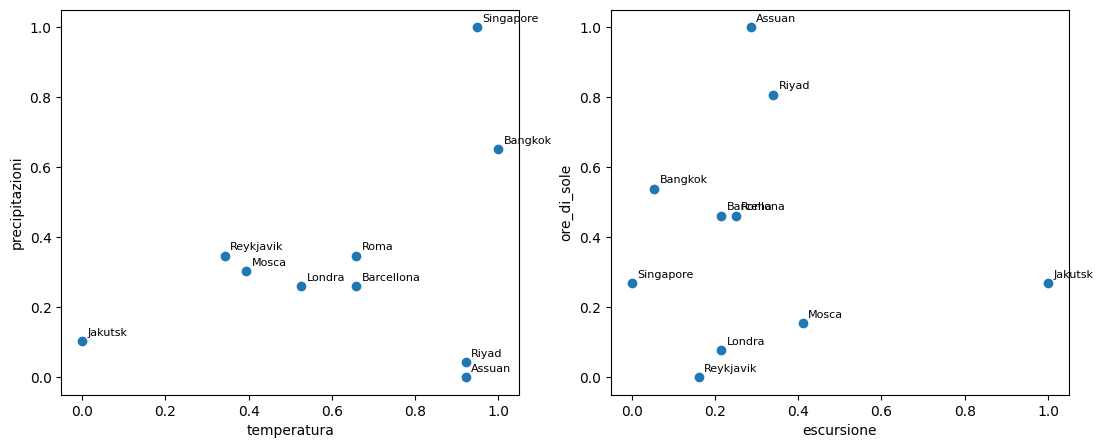

In [15]:
scalata4 = (tabella4 - tabella4.min()) / (tabella4.max() - tabella4.min())

def disegna(ax, tab, x, y):
    ax.scatter(tab[x], tab[y])
    for nome, riga in tab.iterrows():
        ax.annotate(nome, (riga[x], riga[y]), xytext=(4, 4), textcoords='offset points', fontsize=8)
    ax.set_xlabel(x)
    ax.set_ylabel(y)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
disegna(ax1, scalata4, 'temperatura', 'precipitazioni')
disegna(ax2, scalata4, 'escursione', 'ore_di_sole')
plt.show()

Ogni grafico mostra solo una fetta dei dati. Nel primo Londra e Roma sembrano vicine, nel secondo no. Nessuna proiezione da sola ci dice quanto due città siano vicine *in tutte le dimensioni insieme*.

La matematica però non ha questo limite. Le formule che abbiamo scritto per due componenti si estendono a $n$ componenti sostituendo i due termini con una somma:

$$d(a, b) = \sqrt{\sum_{i=1}^{n} (a_i - b_i)^2} \qquad a \cdot b = \sum_{i=1}^{n} a_i b_i \qquad \|a\| = \sqrt{\sum_{i=1}^{n} a_i^2}$$

Le nostre funzioni usano `np.sum` su tutto il vettore e quindi non sapevano nulla del numero di colonne. Possiamo usarle così come sono.

In [16]:
londra2 = scalata.loc['Londra']
londra4 = scalata4.loc['Londra']

print('componenti:', len(londra2), 'e', len(londra4))
print('norma a 2 dimensioni:', round(norma(londra2), 3))
print('norma a 4 dimensioni:', round(norma(londra4), 3))

componenti: 2 e 4
norma a 2 dimensioni: 0.587
norma a 4 dimensioni: 0.63


In [17]:
print('Con 2 caratteristiche')
display(piu_simili(scalata, 'Londra'))
print('Con 4 caratteristiche')
display(piu_simili(scalata4, 'Londra'))

Con 2 caratteristiche


Barcellona    0.131579
Mosca         0.138582
Roma          0.157737
dtype: float64

Con 4 caratteristiche


Reykjavik     0.224251
Mosca         0.252401
Barcellona    0.406500
dtype: float64

### Cosa cambia aggiungendo dimensioni?

- Qual è la città più simile a Londra con due caratteristiche? E con quattro?
- Perché l'aggiunta di escursione termica e ore di sole ha cambiato la risposta? Guardate la tabella: cosa hanno in comune Londra e Reykjavik?
- Riprovate con `similarita_coseno` al posto della distanza euclidea. La città più simile a Londra cambia?
- Che cosa dovremmo fare per aggiungere una quinta caratteristica? Quanto codice dovremmo modificare?

## Cosa abbiamo imparato

1. Un oggetto descritto da $n$ numeri è un **vettore**, cioè un punto in uno spazio a $n$ dimensioni.
2. Confrontare due oggetti significa calcolare una **distanza** o una **similarità** tra i loro vettori. Euclidea, prodotto scalare e coseno rispondono a domande diverse.
3. Le **colonne** sono le dimensioni dello spazio, quindi decidono *su che cosa* due oggetti vengono confrontati.
4. Le formule non dipendono dal numero di dimensioni. Perdiamo la possibilità di disegnare, non quella di calcolare.

Finora le colonne erano misure fatte da qualcuno: gradi, millimetri, ore. Nel prossimo passo i nostri oggetti saranno **testi** e ci chiederemo quali possano essere le loro colonne.

## Dai numeri ai testi

Abbiamo visto che per confrontare degli oggetti ci servono dei vettori, e che le **colonne** del vettore decidono su che cosa li confrontiamo. Per le città le colonne erano misure fisiche. Per un testo, che colonne scegliamo?

Prendiamo quattro descrizioni di città dal nostro dataset. Due sono di città tropicali, una è di una città desertica, una di una città polare.

In [18]:
import json

with open('data/clima_citta.json') as f:
    dataset = json.load(f)

testi = {voce['citta']: voce['testo'] for voce in dataset}
scelte = ['Singapore', 'Giacarta', 'Riyad', 'Reykjavik']

for nome in scelte:
    print(nome)
    print(testi[nome])
    print()

Singapore
A Singapore fa caldo e umido tutto l'anno, con temperature che variano di poco tra una stagione e l'altra. Le piogge sono abbondanti e i temporali pomeridiani arrivano quasi senza preavviso.

Giacarta
Giacarta ha un clima caldo e afoso, con una stagione delle piogge che dura diversi mesi. Gli acquazzoni sono frequenti e le strade si allagano con facilità.

Riyad
Riyad sorge in pieno deserto, dove d'estate il caldo supera facilmente i quaranta gradi. L'aridità è estrema, la pioggia quasi assente e l'escursione termica tra giorno e notte è marcata.

Reykjavik
A Reykjavik gli inverni sono lunghi e bui, con vento freddo e neve frequente. Le estati sono brevi e fresche e il sole di mezzanotte illumina il cielo per settimane.



## Prima idea: contare i caratteri

Il modo più semplice di trasformare un testo in un vettore è contare quante volte compare ciascuna lettera dell'alfabeto. Il testo diventa una riga di 26 numeri, esattamente come la città era una riga di temperatura e precipitazioni.

In [19]:
alfabeto = 'abcdefghijklmnopqrstuvwxyz'

caratteri = pd.DataFrame(
    [[testi[nome].lower().count(c) for c in alfabeto] for nome in scelte],
    index=scelte,
    columns=list(alfabeto),
)
caratteri

,a,b,c,d,e,f,g,h,i,j,...,q,r,s,t,u,v,w,x,y,z
Singapore,22,2,4,5,15,1,4,1,15,0,...,1,11,6,10,5,4,0,0,0,1
Giacarta,17,0,8,5,13,3,6,2,13,0,...,2,5,7,5,5,1,0,0,0,2
Riyad,20,0,5,7,20,1,5,0,15,0,...,2,13,10,13,4,1,0,0,1,0
Reykjavik,6,2,3,3,25,3,2,2,15,1,...,1,7,6,8,4,5,0,0,1,2


Per rendere confrontabili testi di lunghezza diversa guardiamo le frequenze relative, cioè la quota di ciascuna lettera sul totale.

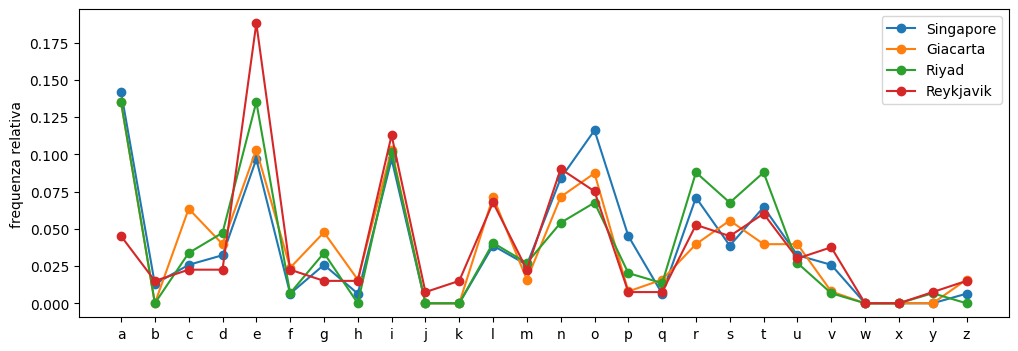

In [20]:
frequenze = caratteri.div(caratteri.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 4))
for nome in scelte:
    ax.plot(list(alfabeto), frequenze.loc[nome], marker='o', label=nome)
ax.set_ylabel('frequenza relativa')
ax.legend()
plt.show()

Calcoliamo ora la similarità del coseno tra tutte le coppie di testi.

In [21]:
def matrice_coseno(tab):
    nomi = tab.index
    return pd.DataFrame(
        [[similarita_coseno(tab.loc[a], tab.loc[b]) for b in nomi] for a in nomi],
        index=nomi, columns=nomi,
    )

matrice_coseno(caratteri).round(2)

,Singapore,Giacarta,Riyad,Reykjavik
Singapore,1.00,0.94,0.95,0.85
Giacarta,0.94,1.00,0.94,0.87
Riyad,0.95,0.94,1.00,0.88
Reykjavik,0.85,0.87,0.88,1.00


### Le lettere distinguono i testi?

- Guardate il grafico: le quattro linee si somigliano? Dove si staccano di più?
- Nella matrice, quale coppia di testi risulta più simile? È la coppia che vi aspettavate?
- Che cosa ci dice una lettera come la *e* sul contenuto di una descrizione di clima? E la *z*?
- Se cambiassimo l'argomento dei testi (cucina, politica, sport) i profili delle lettere cambierebbero molto?

Una lettera, da sola, non significa nulla. Le frequenze delle lettere dipendono dalla **lingua** in cui scriviamo e non da ciò di cui parliamo, e quindi tutti i testi italiani hanno più o meno lo stesso profilo. Le nostre colonne non trasportano **significato**, e di conseguenza non riusciamo a distinguere un testo sul deserto da uno sul ghiaccio.

Serve un'unità che porti significato, e l'unità più naturale è la **parola**. «Pioggia», «deserto» o «neve» dicono qualcosa sull'argomento. Il testo diventerà una riga di conteggi di parole, una colonna per ogni parola che compare nei testi.

## Seconda idea: contare le parole

Prima di contare dobbiamo dividere il testo in parole. Per ora usiamo uno strumento già pronto, il `word_tokenize` di NLTK configurato per l'italiano. Come funziona lo vedremo in un prossimo notebook.

In [22]:
from nltk.tokenize import word_tokenize

parole = {
    nome: [t.lower() for t in word_tokenize(testi[nome], language='italian') if t.isalpha()]
    for nome in scelte
}

parole['Giacarta']

['giacarta',
 'ha',
 'un',
 'clima',
 'caldo',
 'e',
 'afoso',
 'con',
 'una',
 'stagione',
 'delle',
 'piogge',
 'che',
 'dura',
 'diversi',
 'mesi',
 'gli',
 'acquazzoni',
 'sono',
 'frequenti',
 'e',
 'le',
 'strade',
 'si',
 'allagano',
 'con',
 'facilità']

Ogni testo è ora una lista di parole. Le colonne della nostra tabella saranno tutte le parole diverse che compaiono almeno una volta nei quattro testi.

In [23]:
vocabolario = sorted(set(p for lista in parole.values() for p in lista))
print(len(vocabolario), 'parole diverse')

conteggi = pd.DataFrame(
    [[parole[nome].count(p) for p in vocabolario] for nome in scelte],
    index=scelte,
    columns=vocabolario,
)
conteggi

80 parole diverse


,a,abbondanti,acquazzoni,afoso,allagano,arrivano,assente,brevi,bui,caldo,...,temporali,termica,tra,tutto,umido,un,una,variano,vento,è
Singapore,1,1,0,0,0,1,0,0,0,1,...,1,0,1,1,1,0,1,1,0,0
Giacarta,0,0,1,1,1,0,0,0,0,1,...,0,0,0,0,0,1,1,0,0,0
Riyad,0,0,0,0,0,0,1,0,0,1,...,0,1,1,0,0,0,0,0,0,2
Reykjavik,1,0,0,0,0,0,0,1,1,0,...,0,0,0,0,0,0,0,0,1,0


In [24]:
matrice_coseno(conteggi).round(2)

,Singapore,Giacarta,Riyad,Reykjavik
Singapore,1.00,0.46,0.30,0.45
Giacarta,0.46,1.00,0.16,0.37
Riyad,0.30,0.16,1.00,0.26
Reykjavik,0.45,0.37,0.26,1.00


### Cosa è cambiato?

- Quale coppia di testi è ora la più simile? Corrisponde al clima delle città?
- Il testo di Riyad è molto distante dagli altri, anche se parla di caldo come Singapore e Giacarta. Perché?
- Singapore e Reykjavik risultano più simili di quanto ci aspetteremmo. Quali parole hanno in comune? Dicono qualcosa sul clima?

Per rispondere all'ultima domanda guardiamo le colonne in cui entrambi i testi hanno almeno un conteggio.

In [25]:
condivise = conteggi.loc[['Singapore', 'Reykjavik']].T
condivise[(condivise > 0).all(axis=1)]

,Singapore,Reykjavik
a,1,1
con,1,1
di,1,1
e,3,4
le,1,1
sono,1,2


Le parole in comune sono quasi tutte parole grammaticali: articoli, congiunzioni, preposizioni. Servono a costruire la frase ma non dicono nulla sul clima. Ci aspettiamo che la ricerca e la classificazione migliorino se le sapremo trattare in modo diverso dalle parole che portano contenuto. Ci arriveremo nei prossimi notebook, insieme a una domanda che abbiamo lasciato aperta: **come si divide davvero un testo in parole?**